# Data Warehouse: Cobertura da Atenção Básica em São Carlos
**SCC0245 – Processamento Analítico de Dados · Trabalho Prático 1**

Este notebook faz o ciclo completo do data warehouse:

1. **Extração** dos dados reais do DATASUS (CNES, SIH-SUS e SIA-SUS) via PySUS, mais IBGE e API de dados abertos do Ministério da Saúde.
2. **Transformação e integração** (padronização de códigos, sexo, idade, município etc.).
3. **Carga** em um esquema multidimensional (constelação de fatos) no DuckDB.
4. **Consultas OLAP**: roll-up, drill-down, slice and dice, pivot e drill-across.

**Repositório:** https://github.com/germanojorge/dw-aps-sao-carlos

**Como rodar:** execute a célula de instalação uma vez e depois todas as células em ordem.
Os dados reais de 2023–2024, já filtrados para São Carlos, estão salvos em `dados/staging` (e as tabelas do IBGE
e da API do CNES em `dados/referencia`). Se elas não estiverem na pasta (por exemplo, na versão entregue sem os dados), a seção 1.1 baixa
do GitHub (~13 MB). Com essas pastas presentes, **nada é baixado de novo**: o notebook só
reconstrói o DW a partir delas (poucos minutos). Para baixar outro período, mude `ANOS`; só os meses que faltam são baixados.
`MODO_TESTE = True` restringe a janeiro do último ano, útil para testar mudanças rapidamente.

In [ ]:
# Rode uma vez
%pip install -q pysus duckdb pandas pyarrow requests matplotlib

## 1. Configuração

In [2]:
from pathlib import Path

MUN_ALVO   = "354890"      # São Carlos, código IBGE de 6 dígitos (padrão DATASUS)
MUN_ALVO_7 = "3548906"     # mesmo código com 7 dígitos (padrão IBGE)
NOME_MUN   = "São Carlos"
POP_MUN    = 254_857       # população Censo 2022 (IBGE), conferida na API do IBGE (agregado 9514)

ANOS  = [2023, 2024]
MESES = list(range(1, 13))

MODO_TESTE = False         # True: só janeiro do último ano (rápido). False: período completo.
if MODO_TESTE:
    ANOS, MESES = [ANOS[-1]], [1]

USAR_SIA       = True      # o SIA de SP é o arquivo mais pesado; False pula a produção ambulatorial
APAGAR_BRUTOS  = True      # apaga os arquivos estaduais baixados depois de filtrar São Carlos
USAR_API_CNES  = True      # busca nome, bairro e coordenadas dos estabelecimentos

DIR   = Path("dados")
STG   = DIR / "staging"     # dados reais já filtrados para São Carlos (2023–2024 salvos aqui;
                           # se o arquivo do mês existe, o download é pulado)
REF   = DIR / "referencia"  # tabelas auxiliares (IBGE, API CNES)
DWDIR = DIR / "dw"          # tabelas finais do DW em parquet
for d in (STG, REF, DWDIR):
    d.mkdir(parents=True, exist_ok=True)
DB_PATH = DIR / "dw_aps_sao_carlos.duckdb"

COMPETENCIAS = [(a, m) for a in ANOS for m in MESES]
print(f"{len(COMPETENCIAS)} competências: {COMPETENCIAS[0]} a {COMPETENCIAS[-1]}")

24 competências: (2023, 1) a (2024, 12)


### 1.1 Dados do GitHub

Os dados de 2023–2024 já filtrados para São Carlos ficam no repositório do trabalho
(https://github.com/germanojorge/dw-aps-sao-carlos, pasta `notebook/dados`). Se `dados/staging` ou `dados/referencia`
estiverem vazias, esta célula baixa os arquivos de lá; os que já existem são mantidos.


In [ ]:
import requests

GITHUB_REPO = "germanojorge/dw-aps-sao-carlos"
BAIXAR_DO_GITHUB = True   # False: baixa tudo do DATASUS (horas, por causa do SIA)

def baixar_do_github(pasta_repo, destino):
    url = f"https://api.github.com/repos/{GITHUB_REPO}/contents/{pasta_repo}?ref=main"
    itens = requests.get(url, timeout=30).json()
    novos = 0
    for it in itens:
        alvo = destino / it["name"]
        if it["type"] != "file" or alvo.exists():
            continue
        r = requests.get(it["download_url"], timeout=120)
        r.raise_for_status()
        alvo.write_bytes(r.content)
        novos += 1
    print(f"{pasta_repo}: {novos} arquivo(s) baixado(s), {len(itens) - novos} já existiam")

if BAIXAR_DO_GITHUB:
    try:
        baixar_do_github("notebook/dados/staging", STG)
        baixar_do_github("notebook/dados/referencia", REF)
    except Exception as e:
        print("Não foi possível baixar do GitHub, os dados virão do DATASUS:", e)


## 2. Extração

Cada base do DATASUS vem em arquivos **estaduais e mensais** (SP inteiro). Para não estourar a memória,
os arquivos são lidos em lotes, só com as colunas necessárias, e só as linhas de São Carlos são guardadas:

| Base | Grupo | O que é | Filtro aplicado |
|---|---|---|---|
| CNES | EP | Equipes de saúde | equipe em São Carlos |
| CNES | ST | Estabelecimentos | SP inteiro, só dezembro de cada ano (é pequeno) |
| SIH | RD | Internações (AIH reduzida) | paciente residente **ou** internado em São Carlos |
| SIA | PA | Produção ambulatorial | paciente residente **ou** atendido em São Carlos |

In [3]:
import os, shutil, time
from pathlib import Path
import pandas as pd
import pyarrow.dataset as ds
import pysus

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_rows", 12)     # tabelas longas mostram início e fim
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")   # valores sem notação científica

COLS_EP = ["CNES", "CODUFMUN", "IDEQUIPE", "TIPO_EQP", "NOME_EQP", "DT_ATIVA", "DT_DESAT", "COMPETEN"]
COLS_ST = ["CNES", "CODUFMUN", "TP_UNID", "TPGESTAO", "VINC_SUS", "COMPETEN"]
COLS_RD = ["N_AIH", "IDENT", "ANO_CMPT", "MES_CMPT", "MUNIC_RES", "MUNIC_MOV", "CNES", "PROC_REA",
           "DIAG_PRINC", "SEXO", "IDADE", "COD_IDADE", "DIAS_PERM", "VAL_TOT", "MORTE", "CAR_INT", "UTI_MES_TO"]
COLS_PA = ["PA_CODUNI", "PA_UFMUN", "PA_MUNPCN", "PA_CMP", "PA_MVM", "PA_PROC_ID", "PA_CBOCOD", "PA_SEXO",
           "PA_IDADE", "PA_QTDPRO", "PA_QTDAPR", "PA_VALPRO", "PA_VALAPR"]

FUNCOES = {"cnes": pysus.cnes, "sih": pysus.sih, "sia": pysus.sia}

# Pastas do FTP do DATASUS, usadas quando o PySUS não acha o arquivo
FTP = "ftp://ftp.datasus.gov.br/dissemin/publicos/"
PASTAS_FTP = {"sih": "SIHSUS/200801_/Dados/", "sia": "SIASUS/200801_/Dados/", "cnes": "CNES/200508_/Dados/{grupo}/"}


def baixar_ftp(base, grupo, ano, mes):
    # Baixa o .dbc direto do FTP (SIA pode vir dividido em PASP2401a, b, c...),
    # converte para .dbf com pyreaddbc e lê com dbfread.
    import re, urllib.request, pyreaddbc, dbfread
    pasta = FTP + PASTAS_FTP[base].format(grupo=grupo)
    nomes = urllib.request.urlopen(pasta, timeout=120).read().decode().split()
    alvo = re.compile(rf"^{grupo}SP{ano % 100:02d}{mes:02d}[a-z]?\.dbc$", re.I)
    partes = []
    for nome in sorted(n for n in nomes if alvo.match(n)):
        local = Path("dados/ftp") / nome
        local.parent.mkdir(parents=True, exist_ok=True)
        if not local.exists():
            urllib.request.urlretrieve(pasta + nome, local)
        dbf = local.with_suffix(".dbf")
        pyreaddbc.dbc2dbf(str(local), str(dbf))
        partes.append(pd.DataFrame(iter(dbfread.DBF(str(dbf), encoding="iso-8859-1", char_decode_errors="ignore"))))
        dbf.unlink()
        if APAGAR_BRUTOS:
            local.unlink()
    if not partes:
        raise FileNotFoundError(f"nenhum arquivo {base}-{grupo} para {mes:02d}/{ano}")
    return pd.concat(partes, ignore_index=True)


def baixar(base, grupo, ano, mes):
    # Baixa um mês de SP. Tenta o catálogo do PySUS; se falhar ou vier vazio, o FTP do DATASUS.
    f = FUNCOES[base]
    try:
        r = f(state="SP", year=ano, month=mes, group=grupo)
    except Exception as e:
        print(f"catálogo falhou ({type(e).__name__})", end=" ")
        r = []
    if isinstance(r, pd.DataFrame):
        return r
    r = r if isinstance(r, (list, tuple)) else [r]
    if not r:
        print("tentando FTP...", end=" ")
        return baixar_ftp(base, grupo, ano, mes)
    return [str(getattr(p, "path", p)) for p in r]


def _lotes(fonte, colunas):
    if isinstance(fonte, pd.DataFrame):
        yield fonte
        return
    for p in fonte:
        d = ds.dataset(p, format="parquet")
        nomes = {n.upper(): n for n in d.schema.names}
        faltando = [c for c in colunas if c not in nomes]
        if faltando:
            print(f"(colunas ausentes: {faltando})", end=" ")
        for lote in d.to_batches(columns=[nomes[c] for c in colunas if c in nomes], batch_size=500_000):
            yield lote.to_pandas()


def cod6(s):
    # Normaliza códigos de município para 6 dígitos em texto (IBGE 7 dígitos -> 6).
    return s.astype(str).str.strip().str.replace(r"\.0$", "", regex=True).str[:6]


def ler_filtrado(fonte, colunas, filtro_cols=None, valores=None):
    partes = []
    for df in _lotes(fonte, colunas):
        df.columns = [c.upper() for c in df.columns]
        if filtro_cols:
            mask = pd.Series(False, index=df.index)
            for c in filtro_cols:
                if c in df.columns:
                    mask |= cod6(df[c]).isin(valores)
            df = df[mask]
        partes.append(df[[c for c in colunas if c in df.columns]].copy())
    return pd.concat(partes, ignore_index=True) if partes else pd.DataFrame(columns=colunas)


def apagar(fonte):
    if isinstance(fonte, pd.DataFrame):
        return
    for p in fonte:
        try:
            shutil.rmtree(p) if os.path.isdir(p) else os.remove(p)
        except OSError:
            pass


falhas = []

def extrair(tag, base, grupo, ano, mes, colunas, filtro_cols=None, valores=None):
    destino = STG / f"{tag}_{ano}{mes:02d}.parquet"
    if destino.exists():
        return
    t = time.time()
    print(f"{tag} {mes:02d}/{ano}:", end=" ")
    try:
        fonte = baixar(base, grupo, ano, mes)
        df = ler_filtrado(fonte, colunas, filtro_cols, valores)
        df.astype(str).to_parquet(destino, index=False)   # tudo como texto no staging
        if APAGAR_BRUTOS:
            apagar(fonte)
        print(f"{len(df):,} linhas ({time.time() - t:.0f}s)")
    except Exception as e:
        falhas.append((tag, ano, mes, repr(e)))
        print(f"ERRO -> {e}")

In [4]:
for ano, mes in COMPETENCIAS:
    extrair("cnes_ep", "cnes", "EP", ano, mes, COLS_EP, ["CODUFMUN"], {MUN_ALVO})
    extrair("sih_rd",  "sih",  "RD", ano, mes, COLS_RD, ["MUNIC_RES", "MUNIC_MOV"], {MUN_ALVO})
    if USAR_SIA:
        extrair("sia_pa", "sia", "PA", ano, mes, COLS_PA, ["PA_UFMUN", "PA_MUNPCN"], {MUN_ALVO})
    if mes == MESES[-1]:
        extrair("cnes_st", "cnes", "ST", ano, mes, COLS_ST)

print("\nFalhas:", falhas if falhas else "nenhuma")


Falhas: nenhuma


In [5]:
def juntar(tag):
    arqs = [STG / f"{tag}_{a}{m:02d}.parquet" for a, m in COMPETENCIAS]
    arqs = [a for a in arqs if a.exists()]
    if not arqs:
        print(f"{tag}: sem dados")
        return pd.DataFrame()
    return pd.concat([pd.read_parquet(a) for a in arqs], ignore_index=True)

ep, st, rd = juntar("cnes_ep"), juntar("cnes_st"), juntar("sih_rd")
pa = juntar("sia_pa") if USAR_SIA else pd.DataFrame(columns=COLS_PA)

for nome, df in [("CNES-EP", ep), ("CNES-ST", st), ("SIH-RD", rd), ("SIA-PA", pa)]:
    print(f"{nome:8s} {len(df):>10,} linhas | colunas: {list(df.columns)}")

CNES-EP       1,815 linhas | colunas: ['CNES', 'CODUFMUN', 'IDEQUIPE', 'TIPO_EQP', 'NOME_EQP', 'DT_ATIVA', 'DT_DESAT', 'COMPETEN']
CNES-ST     285,417 linhas | colunas: ['CNES', 'CODUFMUN', 'TP_UNID', 'TPGESTAO', 'VINC_SUS', 'COMPETEN']
SIH-RD       39,660 linhas | colunas: ['N_AIH', 'IDENT', 'ANO_CMPT', 'MES_CMPT', 'MUNIC_RES', 'MUNIC_MOV', 'CNES', 'PROC_REA', 'DIAG_PRINC', 'SEXO', 'IDADE', 'COD_IDADE', 'DIAS_PERM', 'VAL_TOT', 'MORTE', 'CAR_INT', 'UTI_MES_TO']
SIA-PA    1,677,903 linhas | colunas: ['PA_CODUNI', 'PA_UFMUN', 'PA_MUNPCN', 'PA_CMP', 'PA_MVM', 'PA_PROC_ID', 'PA_CBOCOD', 'PA_SEXO', 'PA_IDADE', 'PA_QTDPRO', 'PA_QTDAPR', 'PA_VALPRO', 'PA_VALAPR']


### 2.1 Olhando os dados brutos

Vale rodar e olhar com calma: os códigos que aparecem aqui são os que vão virar atributos das dimensões.

In [6]:
if len(ep):
    print("Tipos de equipe (TIPO_EQP):"); print(ep["TIPO_EQP"].value_counts().head(15), "\n")
if len(rd):
    print("SIH – sexo (SEXO):"); print(rd["SEXO"].value_counts(), "\n")
    print("SIH – residentes x internados em São Carlos:")
    print(pd.crosstab(cod6(rd["MUNIC_RES"]) == MUN_ALVO, cod6(rd["MUNIC_MOV"]) == MUN_ALVO,
                      rownames=["residente"], colnames=["internado em SC"]), "\n")
if len(pa):
    print("SIA – sexo (PA_SEXO):"); print(pa["PA_SEXO"].value_counts())

Tipos de equipe (TIPO_EQP):
TIPO_EQP
71    770
70    576
76    301
22     48
73     24
04     24
01     24
23     24
72     24
Name: count, dtype: int64 

SIH – sexo (SEXO):
SEXO
3    21108
1    18552
Name: count, dtype: int64 

SIH – residentes x internados em São Carlos:
internado em SC  False  True 
residente                    
False                0   6810
True              3282  29568 

SIA – sexo (PA_SEXO):
PA_SEXO
F    896634
M    679745
0    101524
Name: count, dtype: int64


### 2.2 Fontes auxiliares

- **IBGE (API de localidades):** nomes dos municípios de SP e hierarquia região imediata → região intermediária → UF.
- **API de Dados Abertos do Ministério da Saúde (CNES):** nome fantasia, bairro e coordenadas dos estabelecimentos.

As duas têm cache em `dados/referencia`. Se a internet falhar, o notebook segue com valores genéricos.

In [7]:
import requests, json

def ibge_municipios_sp():
    cache = REF / "ibge_municipios_sp.csv"
    if cache.exists():
        return pd.read_csv(cache, dtype=str)
    try:
        url = "https://servicodados.ibge.gov.br/api/v1/localidades/estados/35/municipios"
        dados = requests.get(url, timeout=30).json()
        linhas = []
        for m in dados:
            ri = m.get("regiao-imediata") or {}
            rint = ri.get("regiao-intermediaria") or {}
            linhas.append({"cod_municipio_7": str(m["id"]), "cod_municipio": str(m["id"])[:6],
                           "municipio": m["nome"], "regiao_imediata": ri.get("nome", "Não informada"),
                           "regiao_intermediaria": rint.get("nome", "Não informada"), "uf": "SP"})
        df = pd.DataFrame(linhas)
        df.to_csv(cache, index=False)
        return df
    except Exception as e:
        print("IBGE indisponível:", e)
        return pd.DataFrame(columns=["cod_municipio_7", "cod_municipio", "municipio",
                                     "regiao_imediata", "regiao_intermediaria", "uf"])


def api_cnes(codigos):
    cache = REF / "api_cnes_estabelecimentos.csv"
    antigo = pd.read_csv(cache, dtype=str) if cache.exists() else pd.DataFrame(columns=["cnes"])
    faltam = sorted(set(codigos) - set(antigo["cnes"]))
    if not USAR_API_CNES or not faltam:
        return antigo
    print(f"Consultando {len(faltam)} estabelecimentos na API do CNES...")
    campos = ["nome_fantasia", "bairro_estabelecimento", "codigo_tipo_unidade", "codigo_municipio",
              "latitude_estabelecimento_decimo_grau", "longitude_estabelecimento_decimo_grau"]
    novos, erros, s = [], 0, requests.Session()
    for i, c in enumerate(faltam):
        if erros >= 5 and not novos:
            print("API do CNES indisponível; seguindo sem ela.")
            break
        try:
            r = s.get(f"https://apidadosabertos.saude.gov.br/cnes/estabelecimentos/{int(c)}", timeout=15)
            if not r.ok:
                erros += 1
                continue
            j = r.json()
            if isinstance(j, dict) and "estabelecimentos" in j:
                j = (j["estabelecimentos"] or [{}])[0]
            if j:
                novos.append({"cnes": c, **{k: j.get(k) for k in campos}})
        except Exception:
            erros += 1
        if i and i % 100 == 0:
            print(f"  {i}/{len(faltam)}")
    df = pd.concat([antigo, pd.DataFrame(novos)], ignore_index=True).astype(str)
    df.to_csv(cache, index=False)
    return df

ibge = ibge_municipios_sp()
print(f"IBGE: {len(ibge)} municípios")

IBGE: 645 municípios


### 2.3 Tabelas de referência

Codificações oficiais usadas para dar significado aos códigos. A lista de **ICSAP** segue a Portaria SAS/MS nº 221/2008 (conferida com o texto oficial da portaria).
Os códigos de tipo de equipe foram conferidos com a tabela `EQUIPE.dbf` dos arquivos auxiliares do CNES (TAB_CNES).

In [8]:
TIPOS_UNIDADE = {
    "01": "Posto de saúde", "02": "Centro de saúde / Unidade básica", "04": "Policlínica",
    "05": "Hospital geral", "07": "Hospital especializado", "15": "Unidade mista",
    "20": "Pronto socorro geral", "21": "Pronto socorro especializado", "22": "Consultório isolado",
    "36": "Clínica / Centro de especialidade", "39": "Unidade de apoio diagnose e terapia",
    "40": "Unidade móvel terrestre", "42": "Unidade móvel de urgência", "43": "Farmácia",
    "50": "Unidade de vigilância em saúde", "62": "Hospital dia", "68": "Central de gestão em saúde",
    "69": "Centro de atenção hemoterápica", "70": "Centro de atenção psicossocial (CAPS)",
    "71": "Centro de apoio à saúde da família", "73": "Pronto atendimento",
    "74": "Polo academia da saúde", "77": "Serviço de atenção domiciliar", "81": "Central de regulação",
    "67": "Laboratório central de saúde pública", "76": "Central de regulação médica das urgências",
    "80": "Laboratório de saúde pública",
}
NIVEL_ATENCAO = {
    "Atenção Primária": {"01", "02", "71", "74"},
    "Urgência e Emergência": {"20", "21", "42", "73"},
    "Hospitalar": {"05", "07", "15", "62"},
    "Atenção Especializada": {"04", "22", "36", "39", "70", "77"},
}
def nivel_atencao(tp):
    return next((n for n, s in NIVEL_ATENCAO.items() if tp in s), "Outros")

TIPOS_EQUIPE = {  # código -> (descrição, categoria); descrições conferidas com EQUIPE.dbf (TAB_CNES do DATASUS)
    "70": ("eSF – Equipe de Saúde da Família", "Saúde da Família"),
    "76": ("eAP – Equipe de Atenção Primária", "Atenção Primária"),
    "71": ("eSB – Equipe de Saúde Bucal", "Saúde Bucal"),
    "72": ("eMulti / NASF", "Multiprofissional"),
    "73": ("eCR – Consultório na Rua", "Outras"),
    "04": ("EACS – Equipe de Agentes Comunitários de Saúde", "Atenção Primária"),
    "22": ("EMAD tipo I – Atenção Domiciliar", "Outras"),
    "23": ("EMAP – Apoio à Atenção Domiciliar", "Outras"),
    "01": ("ESF (codificação antiga)", "Saúde da Família"),
    "02": ("ESF com saúde bucal M1 (antiga)", "Saúde da Família"),
    "03": ("ESF com saúde bucal M2 (antiga)", "Saúde da Família"),
}

GRUPOS_SIGTAP = {
    "01": "Ações de promoção e prevenção em saúde", "02": "Procedimentos com finalidade diagnóstica",
    "03": "Procedimentos clínicos", "04": "Procedimentos cirúrgicos",
    "05": "Transplantes de órgãos, tecidos e células", "06": "Medicamentos",
    "07": "Órteses, próteses e materiais especiais", "08": "Ações complementares da atenção à saúde",
}

CAPITULOS_CID = [
    ("A00", "B99", "I", "Doenças infecciosas e parasitárias"), ("C00", "D48", "II", "Neoplasias"),
    ("D50", "D89", "III", "Sangue e órgãos hematopoéticos"), ("E00", "E90", "IV", "Endócrinas, nutricionais e metabólicas"),
    ("F00", "F99", "V", "Transtornos mentais e comportamentais"), ("G00", "G99", "VI", "Sistema nervoso"),
    ("H00", "H59", "VII", "Olho e anexos"), ("H60", "H95", "VIII", "Ouvido e apófise mastoide"),
    ("I00", "I99", "IX", "Aparelho circulatório"), ("J00", "J99", "X", "Aparelho respiratório"),
    ("K00", "K93", "XI", "Aparelho digestivo"), ("L00", "L99", "XII", "Pele e tecido subcutâneo"),
    ("M00", "M99", "XIII", "Sistema osteomuscular"), ("N00", "N99", "XIV", "Aparelho geniturinário"),
    ("O00", "O99", "XV", "Gravidez, parto e puerpério"), ("P00", "P96", "XVI", "Afecções perinatais"),
    ("Q00", "Q99", "XVII", "Malformações congênitas"), ("R00", "R99", "XVIII", "Sintomas e achados anormais"),
    ("S00", "T98", "XIX", "Lesões e envenenamentos"), ("U00", "U99", "XXII", "Códigos especiais"),
    ("V01", "Y98", "XX", "Causas externas"), ("Z00", "Z99", "XXI", "Fatores que influenciam o estado de saúde"),
]

# ICSAP – Portaria SAS/MS nº 221/2008 (grupo, lista de faixas CID-10 sem ponto)
ICSAP = [
    ("01 Preveníveis por imunização e condições sensíveis",
     "A33-A37 A95 B16 B05-B06 B26 G000 A170 A19 A15-A16 A18 A171-A179 I00-I02 A51-A53 B50-B54 B77"),
    ("02 Gastroenterites infecciosas", "E86 A00-A09"),
    ("03 Anemia", "D50"),
    ("04 Deficiências nutricionais", "E40-E46 E50-E64"),
    ("05 Infecções de ouvido, nariz e garganta", "H66 J00-J03 J06 J31"),
    ("06 Pneumonias bacterianas", "J13-J14 J153-J154 J158-J159 J181"),
    ("07 Asma", "J45-J46"),
    ("08 Doenças pulmonares", "J20-J21 J40-J44 J47"),
    ("09 Hipertensão", "I10-I11"),
    ("10 Angina", "I20"),
    ("11 Insuficiência cardíaca", "I50 J81"),
    ("12 Doenças cerebrovasculares", "I63-I67 I69 G45-G46"),
    ("13 Diabetes mellitus", "E10-E14"),
    ("14 Epilepsias", "G40-G41"),
    ("15 Infecção no rim e trato urinário", "N10-N12 N30 N34 N390"),
    ("16 Infecção da pele e tecido subcutâneo", "A46 L01-L04 L08"),
    ("17 Doença inflamatória de órgãos pélvicos femininos", "N70-N73 N75-N76"),
    ("18 Úlcera gastrointestinal", "K25-K28 K920-K922"),
    ("19 Doenças relacionadas ao pré-natal e parto", "O23 A50 P350"),
]
_ICSAP_REGRAS = []
for grupo, faixas in ICSAP:
    for f in faixas.split():
        ini, fim = (f.split("-") + [f])[:2]
        _ICSAP_REGRAS.append((ini, fim, grupo))

def grupo_icsap(cid):
    for ini, fim, grupo in _ICSAP_REGRAS:
        if ini <= cid[:len(ini)] <= fim:
            return grupo
    return None

def capitulo_cid(cid):
    c3 = cid[:3]
    return next(((n, d) for ini, fim, n, d in CAPITULOS_CID if ini <= c3 <= fim), ("?", "Não informado"))

CARATER_INTERNACAO = {"01": "Eletivo", "02": "Urgência", "03": "Acidente de trabalho",
                      "04": "Acidente de trajeto", "05": "Outros acidentes de trânsito", "06": "Outras lesões"}

CATEGORIAS_CBO = {"2251": "Médico", "2252": "Médico", "2253": "Médico", "2231": "Médico",
                  "2235": "Enfermeiro", "3222": "Técnico/auxiliar de enfermagem",
                  "2232": "Cirurgião-dentista", "5151": "Agente comunitário de saúde"}

# teste rápido
for c in ["J189", "J181", "I10", "E119", "S720"]:
    print(c, "->", grupo_icsap(c), "|", capitulo_cid(c))

J189 -> None | ('X', 'Aparelho respiratório')
J181 -> 06 Pneumonias bacterianas | ('X', 'Aparelho respiratório')
I10 -> 09 Hipertensão | ('IX', 'Aparelho circulatório')
E119 -> 13 Diabetes mellitus | ('IV', 'Endócrinas, nutricionais e metabólicas')
S720 -> None | ('XIX', 'Lesões e envenenamentos')


## 3. Transformação e integração

Aqui aparecem os casos de **integração** pedidos no enunciado, em que o mesmo dado vem com representações diferentes:

| Dado | SIH | SIA | CNES / IBGE | No DW |
|---|---|---|---|---|
| Sexo | `1`, `3` (e `2`) | `M`, `F` | – | `M`, `F`, `I` |
| Idade | valor + unidade (`COD_IDADE`: dias, meses, anos, centenas) | anos | – | faixa etária e ciclo de vida |
| Município | 6 dígitos | 6 dígitos | IBGE: 7 dígitos | 6 dígitos + nome do IBGE |
| Competência | `ANO_CMPT` + `MES_CMPT` | `PA_MVM` (AAAAMM, processamento) | `COMPETEN` (AAAAMM) | `ano_mes` (AAAAMM) |
| Tipo de unidade | – | – | FTP: `"02"` (texto); API: `2` (inteiro) | texto com 2 dígitos |

In [9]:
FAIXAS = [(0, 4, "00-04"), (5, 9, "05-09"), (10, 14, "10-14"), (15, 19, "15-19"), (20, 39, "20-39"),
          (40, 59, "40-59"), (60, 69, "60-69"), (70, 79, "70-79"), (80, 200, "80+")]
CICLO = {"00-04": "Criança", "05-09": "Criança", "10-14": "Adolescente", "15-19": "Adolescente",
         "20-39": "Adulto", "40-59": "Adulto", "60-69": "Idoso", "70-79": "Idoso", "80+": "Idoso"}

def faixa_etaria(anos):
    out = pd.Series("Ignorada", index=anos.index)
    for ini, fim, rot in FAIXAS:
        out[(anos >= ini) & (anos <= fim)] = rot
    return out

def num(s):
    return pd.to_numeric(s, errors="coerce")

def txt(s, n):
    return s.astype(str).str.strip().str.replace(r"\.0$", "", regex=True).str.zfill(n)

# ---------- SIH ----------
if len(rd):
    rd = rd[rd["IDENT"].astype(str).str.strip() != "5"].copy()     # remove AIH de continuação (longa permanência)
    rd["sexo"] = rd["SEXO"].astype(str).str.strip().map({"1": "M", "2": "F", "3": "F"}).fillna("I")
    idade, unid = num(rd["IDADE"]), rd["COD_IDADE"].astype(str).str.strip()
    anos = idade.where(unid.isin(["4", "nan", ""]), pd.NA)
    anos = anos.mask(unid == "5", 100 + idade).mask(unid.isin(["0", "1", "2", "3"]), 0)
    rd["faixa_etaria"] = faixa_etaria(num(anos))
    rd["ano_mes"] = num(rd["ANO_CMPT"]) * 100 + num(rd["MES_CMPT"])
    rd["cnes"] = txt(rd["CNES"], 7)
    rd["cod_proc"] = txt(rd["PROC_REA"], 10)
    rd["cid"] = rd["DIAG_PRINC"].astype(str).str.strip().str.upper().str.replace(".", "", regex=False)
    rd["mun_res"] = cod6(rd["MUNIC_RES"])
    rd["carater"] = txt(rd["CAR_INT"], 2).map(CARATER_INTERNACAO).fillna("Não informado")
    rd["obito"] = rd["MORTE"].astype(str).str.strip().map({"1": "Sim"}).fillna("Não")
    rd["uti"] = (num(rd["UTI_MES_TO"]).fillna(0) > 0).map({True: "Sim", False: "Não"})

# ---------- SIA ----------
if len(pa):
    pa = pa.copy()
    pa["sexo"] = pa["PA_SEXO"].astype(str).str.strip().str.upper().map({"M": "M", "F": "F"}).fillna("I")
    idade = num(pa["PA_IDADE"])
    pa["faixa_etaria"] = faixa_etaria(idade.where(idade < 130))
    # PA_MVM = mês de processamento (o arquivo traz atendimentos atrasados de meses anteriores em PA_CMP);
    # usar o processamento deixa o SIA conforme ao SIH (ANO_CMPT/MES_CMPT também é processamento)
    pa["ano_mes"] = num(pa["PA_MVM"])
    pa["cnes"] = txt(pa["PA_CODUNI"], 7)
    pa["cod_proc"] = txt(pa["PA_PROC_ID"], 10)
    pa["cbo"] = pa["PA_CBOCOD"].astype(str).str.strip()
    pa["mun_res"] = cod6(pa["PA_MUNPCN"])
    for c in ["PA_QTDPRO", "PA_QTDAPR", "PA_VALPRO", "PA_VALAPR"]:
        pa[c] = num(pa[c]).fillna(0)

# ---------- CNES-EP (snapshot mensal de equipes ativas) ----------
if len(ep):
    ep = ep.copy()
    ep["ano_mes"] = num(ep["COMPETEN"])
    # DT_DESAT vem como AAAAMM; 900001 (ou vazio) = equipe nunca desativada
    desat = num(ep["DT_DESAT"])
    ep = ep[desat.isna() | (desat == 900001) | (desat > ep["ano_mes"])]
    ep["cnes"] = txt(ep["CNES"], 7)
    ep["tipo_eqp"] = txt(ep["TIPO_EQP"], 2)
    ep = ep.drop_duplicates(["ano_mes", "cnes", "IDEQUIPE", "tipo_eqp"])

print("Integração do sexo:")
if len(rd): print("  SIH:", rd["sexo"].value_counts().to_dict())
if len(pa): print("  SIA:", pa["sexo"].value_counts().to_dict())

Integração do sexo:
  SIH: {'F': 21081, 'M': 18528}
  SIA: {'F': 896634, 'M': 679745, 'I': 101524}


## 4. Dimensões

Todas as dimensões têm **chave artificial** (`sk_*`) e uma linha `sk = 0` ("Não informado") para registros
cujo código não é encontrado, evitando perder fatos na carga.

In [10]:
def com_sk(df, nome_sk, linha_desconhecido):
    df = df.reset_index(drop=True)
    df.insert(0, nome_sk, range(1, len(df) + 1))
    desconhecido = pd.DataFrame([{nome_sk: 0, **linha_desconhecido}])
    return pd.concat([desconhecido, df], ignore_index=True)

MESES_NOME = ["Jan", "Fev", "Mar", "Abr", "Mai", "Jun", "Jul", "Ago", "Set", "Out", "Nov", "Dez"]

# ---------- dim_tempo: mês ≤ trimestre ≤ semestre ≤ ano ----------
dim_tempo = com_sk(pd.DataFrame([{
    "ano_mes": a * 100 + m, "mes": m, "nome_mes": MESES_NOME[m - 1],
    "trimestre": f"{a}-T{(m - 1) // 3 + 1}", "semestre": f"{a}-S{(m - 1) // 6 + 1}", "ano": a}
    for a in ANOS for m in range(1, 13)]),
    "sk_tempo", {"ano_mes": 0, "mes": 0, "nome_mes": "N/I", "trimestre": "N/I", "semestre": "N/I", "ano": 0})

# ---------- dim_localidade: município ≤ região imediata ≤ região intermediária ≤ UF ----------
UF_POR_CODIGO = {"11": "RO", "12": "AC", "13": "AM", "14": "RR", "15": "PA", "16": "AP", "17": "TO", "21": "MA",
                 "22": "PI", "23": "CE", "24": "RN", "25": "PB", "26": "PE", "27": "AL", "28": "SE", "29": "BA",
                 "31": "MG", "32": "ES", "33": "RJ", "35": "SP", "41": "PR", "42": "SC", "43": "RS", "50": "MS",
                 "51": "MT", "52": "GO", "53": "DF"}
cods_mun = set(ibge["cod_municipio"])
for df in (rd, pa):
    if len(df): cods_mun |= set(df["mun_res"])
loc = ibge.set_index("cod_municipio").reindex(sorted(c for c in cods_mun if c.isdigit())).reset_index()
loc["municipio"] = loc["municipio"].fillna("Município " + loc["cod_municipio"])
loc.loc[loc["cod_municipio"] == MUN_ALVO, "municipio"] = NOME_MUN
loc["uf"] = loc["cod_municipio"].str[:2].map(UF_POR_CODIGO).fillna("N/I")
loc[["regiao_imediata", "regiao_intermediaria"]] = loc[["regiao_imediata", "regiao_intermediaria"]].fillna("Fora de SP / N/I")
dim_localidade = com_sk(loc[["cod_municipio", "municipio", "regiao_imediata", "regiao_intermediaria", "uf"]],
                        "sk_localidade", {"cod_municipio": "N/I", "municipio": "Não informado",
                                          "regiao_imediata": "N/I", "regiao_intermediaria": "N/I", "uf": "N/I"})

# ---------- dim_estabelecimento (fontes: CNES-ST + API CNES + IBGE) ----------
cods_cnes = set()
for df in (ep, rd, pa):
    if len(df): cods_cnes |= set(df["cnes"])
cods_cnes = sorted(c for c in cods_cnes if c.strip("0").isdigit())

st_ult = pd.DataFrame(columns=["cnes", "tp_unid_st", "mun_st", "gestao"])
if len(st):
    st_ult = st.sort_values("COMPETEN").assign(cnes=txt(st["CNES"], 7)).drop_duplicates("cnes", keep="last")
    st_ult = st_ult.rename(columns={"TPGESTAO": "gestao"}).assign(
        tp_unid_st=txt(st_ult["TP_UNID"], 2), mun_st=cod6(st_ult["CODUFMUN"]))[["cnes", "tp_unid_st", "mun_st", "gestao"]]

api = api_cnes(cods_cnes)
est = pd.DataFrame({"cnes": cods_cnes}).merge(st_ult, on="cnes", how="left")
if len(api) and "nome_fantasia" in api.columns:
    est = est.merge(api, on="cnes", how="left")
else:
    for c in ["nome_fantasia", "bairro_estabelecimento", "codigo_tipo_unidade", "codigo_municipio",
              "latitude_estabelecimento_decimo_grau", "longitude_estabelecimento_decimo_grau"]:
        est[c] = pd.NA

# integração: tipo de unidade e município preferem o CNES-ST; a API completa o que faltar
tp_api = est["codigo_tipo_unidade"].astype(str).str.replace(r"\.0$", "", regex=True).str.zfill(2)
est["tipo_unidade_cod"] = est["tp_unid_st"].fillna(tp_api.where(est["codigo_tipo_unidade"].notna()))
est["cod_municipio"] = est["mun_st"].fillna(cod6(est["codigo_municipio"]).where(est["codigo_municipio"].notna()))
est = est.merge(dim_localidade.drop(columns="sk_localidade"), on="cod_municipio", how="left")

dim_estabelecimento = com_sk(pd.DataFrame({
    "cnes": est["cnes"],
    "nome": est["nome_fantasia"].replace({"nan": pd.NA, "None": pd.NA}).fillna("CNES " + est["cnes"]),
    "tipo_unidade_cod": est["tipo_unidade_cod"].fillna("N/I"),
    "tipo_unidade": est["tipo_unidade_cod"].map(TIPOS_UNIDADE).fillna("Tipo " + est["tipo_unidade_cod"].fillna("N/I")),
    "nivel_atencao": est["tipo_unidade_cod"].map(nivel_atencao),
    "gestao": est["gestao"].map({"M": "Municipal", "E": "Estadual", "D": "Dupla"}).fillna("N/I"),
    "bairro": est["bairro_estabelecimento"].replace({"nan": pd.NA, "None": pd.NA}).fillna("N/I"),
    "latitude": num(est["latitude_estabelecimento_decimo_grau"]),
    "longitude": num(est["longitude_estabelecimento_decimo_grau"]),
    "cod_municipio": est["cod_municipio"].fillna("N/I"),
    "municipio": est["municipio"].fillna("N/I"),
    "regiao_imediata": est["regiao_imediata"].fillna("N/I"),
    "uf": est["uf"].fillna("N/I"),
}), "sk_estabelecimento", {"cnes": "N/I", "nome": "Não informado", "tipo_unidade_cod": "N/I",
                           "tipo_unidade": "N/I", "nivel_atencao": "N/I", "gestao": "N/I", "bairro": "N/I",
                           "cod_municipio": "N/I", "municipio": "N/I", "regiao_imediata": "N/I", "uf": "N/I"})

# ---------- dim_tipo_equipe ----------
cods_eqp = sorted(set(ep["tipo_eqp"])) if len(ep) else []
dim_tipo_equipe = com_sk(pd.DataFrame({
    "tipo_equipe_cod": cods_eqp,
    "tipo_equipe": [TIPOS_EQUIPE.get(c, (f"Tipo {c} (conferir)", ""))[0] for c in cods_eqp],
    "categoria_equipe": [TIPOS_EQUIPE.get(c, ("", "Outras"))[1] for c in cods_eqp],
}), "sk_tipo_equipe", {"tipo_equipe_cod": "N/I", "tipo_equipe": "Não informado", "categoria_equipe": "N/I"})

# ---------- dim_procedimento: procedimento ≤ forma de organização ≤ subgrupo ≤ grupo (SIGTAP) ----------
cods_proc = set()
for df in (rd, pa):
    if len(df): cods_proc |= set(df["cod_proc"])
cods_proc = sorted(cods_proc)
dim_procedimento = com_sk(pd.DataFrame({
    "cod_procedimento": cods_proc,
    "forma_organizacao_cod": [c[:6] for c in cods_proc],
    "subgrupo_cod": [c[:4] for c in cods_proc],
    "grupo_cod": [c[:2] for c in cods_proc],
    "grupo": [GRUPOS_SIGTAP.get(c[:2], "Não informado") for c in cods_proc],
}), "sk_procedimento", {"cod_procedimento": "N/I", "forma_organizacao_cod": "N/I",
                        "subgrupo_cod": "N/I", "grupo_cod": "N/I", "grupo": "Não informado"})

# ---------- dim_diagnostico: CID ≤ categoria (3 caracteres) ≤ capítulo; + classificação ICSAP ----------
cids = sorted(set(rd["cid"])) if len(rd) else []
caps = [capitulo_cid(c) for c in cids]
gicsap = [grupo_icsap(c) for c in cids]
dim_diagnostico = com_sk(pd.DataFrame({
    "cid": cids, "cid_categoria": [c[:3] for c in cids],
    "capitulo_num": [c[0] for c in caps], "capitulo": [c[1] for c in caps],
    "icsap": ["Sim" if g else "Não" for g in gicsap],
    "grupo_icsap": [g or "Não ICSAP" for g in gicsap],
}), "sk_diagnostico", {"cid": "N/I", "cid_categoria": "N/I", "capitulo_num": "N/I",
                       "capitulo": "Não informado", "icsap": "N/I", "grupo_icsap": "N/I"})

# ---------- dim_perfil_paciente (sexo; faixa etária ≤ ciclo de vida) ----------
perfis = [(s, f) for s in ["M", "F", "I"] for f in [r for _, _, r in FAIXAS] + ["Ignorada"]]
dim_perfil_paciente = com_sk(pd.DataFrame({
    "sexo": [s for s, _ in perfis],
    "sexo_desc": [{"M": "Masculino", "F": "Feminino", "I": "Ignorado"}[s] for s, _ in perfis],
    "faixa_etaria": [f for _, f in perfis],
    "ciclo_vida": [CICLO.get(f, "Ignorado") for _, f in perfis],
}), "sk_perfil", {"sexo": "N/I", "sexo_desc": "N/I", "faixa_etaria": "N/I", "ciclo_vida": "N/I"})

# ---------- dim_cbo: ocupação ≤ família (4 dígitos) ≤ categoria profissional ----------
cbos = sorted(set(pa["cbo"])) if len(pa) else []
dim_cbo = com_sk(pd.DataFrame({
    "cbo": cbos, "familia_cbo": [c[:4] for c in cbos],
    "categoria_profissional": [CATEGORIAS_CBO.get(c[:4], "Outros profissionais") for c in cbos],
}), "sk_cbo", {"cbo": "N/I", "familia_cbo": "N/I", "categoria_profissional": "N/I"})

# ---------- dim_junk_internacao (tabela bugiganga): caráter × óbito × UTI ----------
combos = rd[["carater", "obito", "uti"]].drop_duplicates() if len(rd) else pd.DataFrame(columns=["carater", "obito", "uti"])
dim_junk_internacao = com_sk(combos.sort_values(list(combos.columns)).rename(columns={"carater": "carater_atendimento"}),
                             "sk_junk", {"carater_atendimento": "N/I", "obito": "N/I", "uti": "N/I"})

DIMENSOES = {"dim_tempo": dim_tempo, "dim_localidade": dim_localidade, "dim_estabelecimento": dim_estabelecimento,
             "dim_tipo_equipe": dim_tipo_equipe, "dim_procedimento": dim_procedimento,
             "dim_diagnostico": dim_diagnostico, "dim_perfil_paciente": dim_perfil_paciente,
             "dim_cbo": dim_cbo, "dim_junk_internacao": dim_junk_internacao}
for n, d in DIMENSOES.items():
    print(f"{n:22s} {len(d):>7,} linhas")

dim_tempo                   25 linhas
dim_localidade           1,008 linhas
dim_estabelecimento        690 linhas
dim_tipo_equipe              8 linhas
dim_procedimento         2,381 linhas
dim_diagnostico          3,004 linhas
dim_perfil_paciente         31 linhas
dim_cbo                     97 linhas
dim_junk_internacao         12 linhas


## 5. Tabelas de fatos

| Fato | Grão | Tipo | Medidas |
|---|---|---|---|
| `fato_equipe` | uma equipe ativa em um mês | **fato sem fato** (snapshot periódico) | contagem de linhas (`COUNT`); semiaditiva no tempo |
| `fato_producao_ambulatorial` | estabelecimento × procedimento × mês × perfil × município de residência × CBO | transacional agregada | quantidades e valores (aditivos); taxa de aprovação é derivada e não aditiva |
| `fato_internacao` | uma internação (AIH) | transacional | contagem, dias de permanência, valor (aditivos); `n_aih` é **dimensão degenerada** |

In [11]:
def chave(df, dim, col_df, col_dim, sk):
    m = dict(zip(dim[col_dim], dim[sk]))
    return df[col_df].map(m).fillna(0).astype(int)

# ---------- fato_equipe (fato sem fato) ----------
if len(ep):
    fato_equipe = pd.DataFrame({
        "sk_tempo": chave(ep, dim_tempo, "ano_mes", "ano_mes", "sk_tempo"),
        "sk_estabelecimento": chave(ep, dim_estabelecimento, "cnes", "cnes", "sk_estabelecimento"),
        "sk_tipo_equipe": chave(ep, dim_tipo_equipe, "tipo_eqp", "tipo_equipe_cod", "sk_tipo_equipe"),
        "id_equipe": ep["IDEQUIPE"].astype(str).str.strip(),          # dimensão degenerada
    })
else:
    fato_equipe = pd.DataFrame(columns=["sk_tempo", "sk_estabelecimento", "sk_tipo_equipe", "id_equipe"])

# chave do perfil (sexo + faixa)
perfil_map = {(s, f): k for k, s, f in dim_perfil_paciente[["sk_perfil", "sexo", "faixa_etaria"]].itertuples(index=False)}
def sk_perfil(df):
    return pd.Series([perfil_map.get(t, 0) for t in zip(df["sexo"], df["faixa_etaria"])], index=df.index)

# ---------- fato_internacao ----------
if len(rd):
    fato_internacao = pd.DataFrame({
        "sk_tempo": chave(rd, dim_tempo, "ano_mes", "ano_mes", "sk_tempo"),
        "sk_estabelecimento": chave(rd, dim_estabelecimento, "cnes", "cnes", "sk_estabelecimento"),
        "sk_procedimento": chave(rd, dim_procedimento, "cod_proc", "cod_procedimento", "sk_procedimento"),
        "sk_diagnostico": chave(rd, dim_diagnostico, "cid", "cid", "sk_diagnostico"),
        "sk_perfil": sk_perfil(rd),
        "sk_localidade_residencia": chave(rd, dim_localidade, "mun_res", "cod_municipio", "sk_localidade"),
        "sk_junk": rd.merge(dim_junk_internacao.rename(columns={"carater_atendimento": "carater"}),
                            on=["carater", "obito", "uti"], how="left")["sk_junk"].fillna(0).astype(int).values,
        "n_aih": rd["N_AIH"].astype(str).str.strip(),                 # dimensão degenerada
        "qtd_internacoes": 1,
        "dias_permanencia": num(rd["DIAS_PERM"]).fillna(0).astype(int),
        "valor_total": num(rd["VAL_TOT"]).fillna(0).round(2),
    })
else:
    fato_internacao = pd.DataFrame(columns=["sk_tempo", "sk_estabelecimento", "sk_procedimento", "sk_diagnostico",
                                            "sk_perfil", "sk_localidade_residencia", "sk_junk", "n_aih",
                                            "qtd_internacoes", "dias_permanencia", "valor_total"])

# ---------- fato_producao_ambulatorial ----------
if len(pa):
    fp = pd.DataFrame({
        "sk_tempo": chave(pa, dim_tempo, "ano_mes", "ano_mes", "sk_tempo"),
        "sk_estabelecimento": chave(pa, dim_estabelecimento, "cnes", "cnes", "sk_estabelecimento"),
        "sk_procedimento": chave(pa, dim_procedimento, "cod_proc", "cod_procedimento", "sk_procedimento"),
        "sk_perfil": sk_perfil(pa),
        "sk_localidade_residencia": chave(pa, dim_localidade, "mun_res", "cod_municipio", "sk_localidade"),
        "sk_cbo": chave(pa, dim_cbo, "cbo", "cbo", "sk_cbo"),
        "qtd_apresentada": pa["PA_QTDPRO"], "qtd_aprovada": pa["PA_QTDAPR"],
        "valor_apresentado": pa["PA_VALPRO"], "valor_aprovado": pa["PA_VALAPR"],
    })
    chaves = [c for c in fp.columns if c.startswith("sk_")]
    fato_producao_ambulatorial = fp.groupby(chaves, as_index=False).sum()
    for c in ["qtd_apresentada", "qtd_aprovada"]:
        fato_producao_ambulatorial[c] = fato_producao_ambulatorial[c].astype(int)
    for c in ["valor_apresentado", "valor_aprovado"]:
        fato_producao_ambulatorial[c] = fato_producao_ambulatorial[c].round(2)
else:
    fato_producao_ambulatorial = pd.DataFrame(columns=["sk_tempo", "sk_estabelecimento", "sk_procedimento", "sk_perfil",
                                                       "sk_localidade_residencia", "sk_cbo", "qtd_apresentada",
                                                       "qtd_aprovada", "valor_apresentado", "valor_aprovado"])

FATOS = {"fato_equipe": fato_equipe, "fato_internacao": fato_internacao,
         "fato_producao_ambulatorial": fato_producao_ambulatorial}
for n, f in FATOS.items():
    print(f"{n:28s} {len(f):>10,} linhas")

fato_equipe                       1,686 linhas
fato_internacao                  39,609 linhas
fato_producao_ambulatorial      193,723 linhas


## 6. Carga no DuckDB e checagem de qualidade

O DW é gravado em `dados/dw_aps_sao_carlos.duckdb` (um arquivo, consultável com SQL) e também em parquet em `dados/dw/`.

In [12]:
import duckdb

con = duckdb.connect(str(DB_PATH))
for nome, df in {**DIMENSOES, **FATOS}.items():
    con.register("tmp", df)
    con.execute(f"CREATE OR REPLACE TABLE {nome} AS SELECT * FROM tmp")
    con.unregister("tmp")
    df.to_parquet(DWDIR / f"{nome}.parquet", index=False)

# checagem: quantos fatos caíram no membro "Não informado" (sk = 0) de cada dimensão
for nome, f in FATOS.items():
    if len(f):
        zeros = {c: int((f[c] == 0).sum()) for c in f.columns if c.startswith("sk_")}
        print(nome, {k: v for k, v in zeros.items() if v} or "todas as chaves resolvidas")

def q(sql):
    df = con.sql(sql).df()
    for c in df.select_dtypes("float").columns:   # SUM do DuckDB volta como decimal; inteiros voltam a ser inteiros
        if (df[c].dropna() % 1 == 0).all() and not c.startswith("valor"):
            df[c] = df[c].astype("Int64")
    return df

q("SELECT table_name, estimated_size AS linhas FROM duckdb_tables() ORDER BY table_name")

fato_equipe todas as chaves resolvidas
fato_internacao todas as chaves resolvidas
fato_producao_ambulatorial todas as chaves resolvidas


,table_name,linhas
0,dim_cbo,97
1,dim_diagnostico,3004
2,dim_estabelecimento,690
3,dim_junk_internacao,12
4,dim_localidade,1008
5,dim_perfil_paciente,31
6,dim_procedimento,2381
7,dim_tempo,25
8,dim_tipo_equipe,8
9,fato_equipe,1686


## 7. Consultas OLAP

Nas consultas sobre demanda, o filtro é o **município de residência = São Carlos**: a pergunta de política pública
é sobre a população do município, independentemente de onde ela foi atendida.

### Consulta 1 – Roll-up: internações por condições sensíveis à atenção primária (ICSAP)
Nível mês → trimestre → ano. **Justificativa:** ICSAP é o indicador clássico de efetividade da atenção básica;
acompanhar a tendência mostra se a rede básica está evitando internações.

In [13]:
BASE_ICSAP = f'''
    FROM fato_internacao f
    JOIN dim_tempo t USING (sk_tempo)
    JOIN dim_diagnostico d USING (sk_diagnostico)
    JOIN dim_localidade l ON l.sk_localidade = f.sk_localidade_residencia
    WHERE d.icsap = 'Sim' AND l.cod_municipio = '{MUN_ALVO}'
'''
print("Nível mês:")
display(q(f"SELECT t.ano_mes, SUM(f.qtd_internacoes) AS internacoes_icsap {BASE_ICSAP} GROUP BY 1 ORDER BY 1"))

print("Roll-up para trimestre e ano (linhas com NULL são os subtotais):")
q(f'''SELECT t.ano, t.trimestre, SUM(f.qtd_internacoes) AS internacoes_icsap
      {BASE_ICSAP} GROUP BY ROLLUP (t.ano, t.trimestre) ORDER BY t.ano NULLS LAST, t.trimestre NULLS LAST''')

Nível mês:


,ano_mes,internacoes_icsap
0,202301,210
1,202302,172
2,202303,218
3,202304,236
4,202305,261
...,...,...
19,202408,228
20,202409,221
21,202410,241
22,202411,217


Roll-up para trimestre e ano (linhas com NULL são os subtotais):


,ano,trimestre,internacoes_icsap
0,2023,2023-T1,600
1,2023,2023-T2,728
2,2023,2023-T3,673
3,2023,2023-T4,699
4,2023,None,2700
5,2024,2024-T1,572
6,2024,2024-T2,652
7,2024,2024-T3,659
8,2024,2024-T4,672
9,2024,None,2555


### Consulta 2 – Drill-down: produção ambulatorial por grupo → subgrupo → procedimento
**Justificativa:** mostra que tipo de atendimento ambulatorial a rede de São Carlos mais realiza e permite detalhar
o grupo mais relevante até o procedimento.

In [14]:
BASE_PROD = f'''
    FROM fato_producao_ambulatorial f
    JOIN dim_procedimento p USING (sk_procedimento)
    JOIN dim_estabelecimento e USING (sk_estabelecimento)
    WHERE e.cod_municipio = '{MUN_ALVO}'
'''
g = q(f"SELECT p.grupo_cod, p.grupo, SUM(f.qtd_aprovada) AS qtd_aprovada, SUM(f.valor_aprovado) AS valor_aprovado "
      f"{BASE_PROD} GROUP BY 1, 2 ORDER BY 3 DESC")
display(g)
if len(g):
    grupo = g.iloc[0]["grupo_cod"]
    print(f"Drill-down no grupo {grupo} -> subgrupo:")
    sg = q(f"SELECT p.subgrupo_cod, SUM(f.qtd_aprovada) AS qtd_aprovada {BASE_PROD} AND p.grupo_cod = '{grupo}' "
           f"GROUP BY 1 ORDER BY 2 DESC")
    display(sg)
    if len(sg):
        sub = sg.iloc[0]["subgrupo_cod"]
        print(f"Drill-down no subgrupo {sub} -> procedimento (top 10):")
        display(q(f"SELECT p.cod_procedimento, SUM(f.qtd_aprovada) AS qtd_aprovada {BASE_PROD} "
                  f"AND p.subgrupo_cod = '{sub}' GROUP BY 1 ORDER BY 2 DESC LIMIT 10"))

,grupo_cod,grupo,qtd_aprovada,valor_aprovado
0,02,Procedimentos com finalidade diagnóstica,1767091,"18,015,200.70"
1,03,Procedimentos clínicos,1055094,"31,280,793.32"
2,01,Ações de promoção e prevenção em saúde,73886,"4,375.44"
3,08,Ações complementares da atenção à saúde,36676,"181,546.20"
4,04,Procedimentos cirúrgicos,29067,"3,550,130.60"
5,07,"Órteses, próteses e materiais especiais",699,"599,707.09"


Drill-down no grupo 02 -> subgrupo:


,subgrupo_cod,qtd_aprovada
0,0202,1390094
1,0211,148935
2,0204,84022
3,0205,57799
4,0212,24208
...,...,...
9,0207,6647
10,0201,5823
11,0208,1887
12,0213,50


Drill-down no subgrupo 0202 -> procedimento (top 10):


,cod_procedimento,qtd_aprovada
0,0202020380,126646
1,0202010317,101989
2,0202050017,71391
3,0202010473,67970
4,0202010694,67140
5,0202010600,64799
6,0202010295,59248
7,0202010635,58311
8,0202010678,55490
9,0202010651,52496


### Consulta 3 – Slice and dice: ICSAP em idosos no último ano, por grupo de causa e sexo
**Slice:** ano = último ano do período. **Dice:** ciclo de vida = Idoso e ICSAP = Sim.
**Justificativa:** idosos concentram hipertensão, diabetes e insuficiência cardíaca, condições que a APS deveria controlar.

In [15]:
q(f'''
SELECT d.grupo_icsap, pp.sexo_desc, SUM(f.qtd_internacoes) AS internacoes, ROUND(AVG(f.dias_permanencia), 1) AS media_dias
FROM fato_internacao f
JOIN dim_tempo t USING (sk_tempo)
JOIN dim_diagnostico d USING (sk_diagnostico)
JOIN dim_perfil_paciente pp USING (sk_perfil)
JOIN dim_localidade l ON l.sk_localidade = f.sk_localidade_residencia
WHERE t.ano = {ANOS[-1]} AND pp.ciclo_vida = 'Idoso' AND d.icsap = 'Sim' AND l.cod_municipio = '{MUN_ALVO}'
GROUP BY 1, 2 ORDER BY 3 DESC
''')

,grupo_icsap,sexo_desc,internacoes,media_dias
0,12 Doenças cerebrovasculares,Masculino,170,5.30
1,12 Doenças cerebrovasculares,Feminino,154,4.90
2,11 Insuficiência cardíaca,Feminino,128,7.00
3,11 Insuficiência cardíaca,Masculino,114,9.20
4,10 Angina,Masculino,89,3.00
...,...,...,...,...
28,04 Deficiências nutricionais,Masculino,3,5.00
29,07 Asma,Masculino,2,8.00
30,17 Doença inflamatória de órgãos pélvicos femi...,Feminino,2,4.00
31,03 Anemia,Feminino,1,1.00


### Consulta 4 – Pivot: ICSAP por grupo de causa × ciclo de vida, e a mesma visão rotacionada
**Justificativa:** a rotação dos eixos facilita duas leituras: "quais causas pesam em cada faixa da vida"
e "qual faixa da vida mais sofre com cada causa".

In [16]:
base = q(f"SELECT d.grupo_icsap, pp.ciclo_vida, SUM(f.qtd_internacoes) AS n "
         f"FROM fato_internacao f JOIN dim_diagnostico d USING (sk_diagnostico) "
         f"JOIN dim_perfil_paciente pp USING (sk_perfil) "
         f"JOIN dim_localidade l ON l.sk_localidade = f.sk_localidade_residencia "
         f"WHERE d.icsap = 'Sim' AND l.cod_municipio = '{MUN_ALVO}' GROUP BY 1, 2")
if len(base):
    visao = base.pivot_table(index="grupo_icsap", columns="ciclo_vida", values="n", aggfunc="sum", fill_value=0)
    print("Linhas = causa, colunas = ciclo de vida"); display(visao)
    print("Pivot (eixos rotacionados): linhas = ciclo de vida, colunas = causa")
    with pd.option_context("display.max_columns", 8):   # 19 causas: mostra as primeiras e as últimas
        display(visao.T)

Linhas = causa, colunas = ciclo de vida


ciclo_vida,Adolescente,Adulto,Criança,Idoso
grupo_icsap,,,,
01 Preveníveis por imunização e condições sensíveis,5,58,12,21
02 Gastroenterites infecciosas,3,33,79,51
03 Anemia,0,3,2,3
04 Deficiências nutricionais,1,4,5,13
"05 Infecções de ouvido, nariz e garganta",5,10,41,2
...,...,...,...,...
15 Infecção no rim e trato urinário,15,204,29,299
16 Infecção da pele e tecido subcutâneo,10,189,40,137
17 Doença inflamatória de órgãos pélvicos femininos,10,43,0,3


Pivot (eixos rotacionados): linhas = ciclo de vida, colunas = causa


grupo_icsap,01 Preveníveis por imunização e condições sensíveis,02 Gastroenterites infecciosas,03 Anemia,04 Deficiências nutricionais,...,16 Infecção da pele e tecido subcutâneo,17 Doença inflamatória de órgãos pélvicos femininos,18 Úlcera gastrointestinal,19 Doenças relacionadas ao pré-natal e parto
ciclo_vida,,,,,,,,,
Adolescente,5,3,0,1,...,10,10,2,4
Adulto,58,33,3,4,...,189,43,130,31
Criança,12,79,2,5,...,40,0,6,43
Idoso,21,51,3,13,...,137,3,245,0


### Consulta 5 – Drill-across: oferta de equipes × produção na APS × internações evitáveis
Combina as **três tabelas de fatos** pela dimensão compartilhada `dim_tempo` (e pelo município).
Cada fato é agregado separadamente e só depois os resultados são juntados, que é o que caracteriza o drill-across.

Indicadores derivados:
- **cobertura estimada de Saúde da Família** = nº de equipes × 3.450 pessoas / população (parâmetro clássico do Ministério; aproximação).
- **taxa de ICSAP** por 10 mil habitantes.

**Justificativa:** é a pergunta central do trabalho: mais atenção básica está associada a menos internações evitáveis?

Observação: desde o e-SUS APS, a produção da atenção básica é registrada no SISAB e não no SIA.
Com os dados reais de 2023–2024, as UBS/USF de São Carlos têm **produção zero** no SIA em todos os meses:
a coluna `producao_aps` sai zerada por limitação da fonte, não por erro da consulta.

In [17]:
drill = q(f'''
WITH oferta AS (
    SELECT f.sk_tempo, COUNT(*) AS equipes_sf
    FROM fato_equipe f JOIN dim_tipo_equipe te USING (sk_tipo_equipe)
    JOIN dim_estabelecimento e USING (sk_estabelecimento)
    WHERE te.categoria_equipe = 'Saúde da Família' AND e.cod_municipio = '{MUN_ALVO}'
    GROUP BY 1),
producao AS (
    SELECT f.sk_tempo, SUM(f.qtd_aprovada) AS producao_aps
    FROM fato_producao_ambulatorial f JOIN dim_estabelecimento e USING (sk_estabelecimento)
    WHERE e.nivel_atencao = 'Atenção Primária' AND e.cod_municipio = '{MUN_ALVO}'
    GROUP BY 1),
icsap AS (
    SELECT f.sk_tempo, SUM(f.qtd_internacoes) AS internacoes_icsap
    FROM fato_internacao f JOIN dim_diagnostico d USING (sk_diagnostico)
    JOIN dim_localidade l ON l.sk_localidade = f.sk_localidade_residencia
    WHERE d.icsap = 'Sim' AND l.cod_municipio = '{MUN_ALVO}'
    GROUP BY 1)
SELECT t.ano_mes,
       COALESCE(o.equipes_sf, 0) AS equipes_sf,
       ROUND(LEAST(100, 100.0 * COALESCE(o.equipes_sf, 0) * 3450 / {POP_MUN}), 1) AS cobertura_estimada_pct,
       COALESCE(p.producao_aps, 0) AS producao_aps,
       COALESCE(i.internacoes_icsap, 0) AS internacoes_icsap,
       ROUND(10000.0 * COALESCE(i.internacoes_icsap, 0) / {POP_MUN}, 2) AS taxa_icsap_10mil
FROM dim_tempo t
LEFT JOIN oferta o USING (sk_tempo)
LEFT JOIN producao p USING (sk_tempo)
LEFT JOIN icsap i USING (sk_tempo)
WHERE t.sk_tempo > 0 AND t.ano_mes IN ({", ".join(str(a * 100 + m) for a, m in COMPETENCIAS)})
ORDER BY 1
''')
drill

,ano_mes,equipes_sf,cobertura_estimada_pct,producao_aps,internacoes_icsap,taxa_icsap_10mil
0,202301,23,31.10,0,210,8.24
1,202302,23,31.10,0,172,6.75
2,202303,23,31.10,0,218,8.55
3,202304,23,31.10,0,236,9.26
4,202305,23,31.10,0,261,10.24
...,...,...,...,...,...,...
19,202408,23,31.10,0,228,8.95
20,202409,23,31.10,0,221,8.67
21,202410,23,31.10,0,241,9.46
22,202411,23,31.10,0,217,8.51


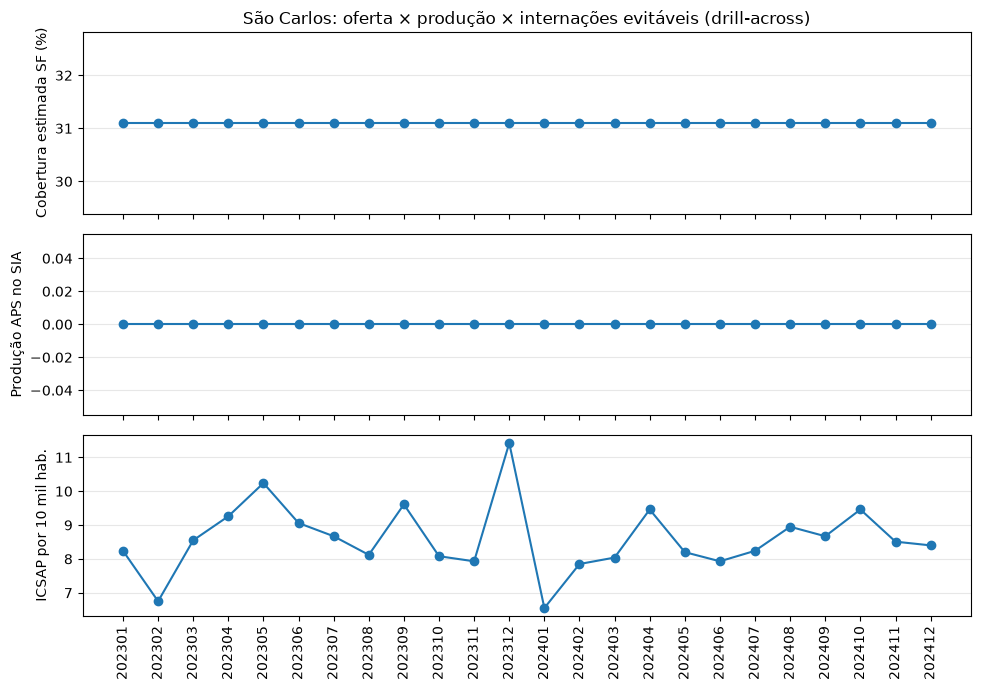

In [18]:
import matplotlib.pyplot as plt

# Um painel por fato, com o mesmo eixo x (mês): as três medidas têm escalas diferentes,
# então ficam em gráficos separados em vez de um gráfico com dois eixos y.
if len(drill) > 1:
    x = drill["ano_mes"].astype(str)
    paineis = [("cobertura_estimada_pct", "Cobertura estimada SF (%)"),
               ("producao_aps", "Produção APS no SIA"),
               ("taxa_icsap_10mil", "ICSAP por 10 mil hab.")]
    fig, eixos = plt.subplots(len(paineis), 1, figsize=(10, 7), sharex=True)
    for ax, (col, rotulo) in zip(eixos, paineis):
        ax.plot(x, drill[col], marker="o", color="tab:blue")
        ax.set_ylabel(rotulo)
        ax.grid(axis="y", alpha=0.3)
    eixos[0].set_title(f"{NOME_MUN}: oferta × produção × internações evitáveis (drill-across)")
    eixos[-1].tick_params(axis="x", rotation=90)
    plt.tight_layout(); plt.show()
else:
    print("Gráfico aparece quando houver mais de um mês (MODO_TESTE = False).")

## 8. Resumo para o relatório

Lista das tabelas, colunas e tipos (útil para escrever a seção de esquemas) e as falhas de download, se houver.

In [19]:
for nome, df in {**DIMENSOES, **FATOS}.items():
    print(f"\n{nome} ({len(df):,} linhas)")
    for c, t in df.dtypes.items():
        print(f"   {c:28s} {t}")
print("\nFalhas de download:", falhas if falhas else "nenhuma")


dim_tempo (25 linhas)
   sk_tempo                     int64
   ano_mes                      int64
   mes                          int64
   nome_mes                     object
   trimestre                    object
   semestre                     object
   ano                          int64

dim_localidade (1,008 linhas)
   sk_localidade                int64
   cod_municipio                object
   municipio                    object
   regiao_imediata              object
   regiao_intermediaria         object
   uf                           object

dim_estabelecimento (690 linhas)
   sk_estabelecimento           int64
   cnes                         object
   nome                         object
   tipo_unidade_cod             object
   tipo_unidade                 object
   nivel_atencao                object
   gestao                       object
   bairro                       object
   cod_municipio                object
   municipio                    object
   regiao_imediata   